> **Bản PyTorch** của `examples/5. Others/1_segnet.ipynb` (Keras). Người chuyển: **TV4 – Huỳnh Viễn Thông** (theo khuôn `2. CNN + MLP/1_MNIST_CNN.ipynb` của TV2).
>
> **Thay đổi so với bản Keras**
> - Ảnh đầu vào Keras `(N, 96, 96, 1)` (channels-last) → PyTorch `(N, 1, 96, 96)` (channels-first), kiểu `float32`, giữ nguyên thang pixel gốc `0–255` như bản Keras.
> - Nhãn phân đoạn Keras dạng one-hot trải phẳng `(N, 96*96, 7)` + tầng `Reshape`/`Permute`/`Activation('softmax')` + `loss='categorical_crossentropy'` → PyTorch dùng nhãn chỉ số lớp nguyên `(N, 96, 96)` kiểu `int64` (`0..6`, pixel ngoài 7 mức xám chuẩn đặt `-100` để `ignore_index=-100`), bỏ `Reshape`/`Permute`/`Softmax` ở đầu ra (mô hình trả về logits `(N, 7, 96, 96)`) và tính trực tiếp bằng `nn.CrossEntropyLoss(ignore_index=-100)`.
> - Khối Encoder: `Conv2D(f, (3,3), padding='same')` + `BatchNormalization()` + `Activation('relu')` + `MaxPooling2D()` → `nn.Conv2d(in_c, f, 3, padding=1)` + `nn.BatchNorm2d(f)` + `nn.ReLU(inplace=True)` + `nn.MaxPool2d(2)` (giữ nguyên `bias=True` như mặc định Keras nên số tham số trùng khớp tuyệt đối: `29,442,325` tham số huấn luyện + `15,886` buffer running mean/var của BN = `29,458,211` như `autoencoder.summary()` bản Keras).
> - Khối Decoder: `UpSampling2D()` → `nn.Upsample(scale_factor=2, mode='nearest')`, lớp cuối `Conv2D(7, (1,1), padding='valid')` + `BatchNormalization()` → `nn.Conv2d(64, 7, 1, padding=0)` + `nn.BatchNorm2d(7)`.
> - Hàm `summary`, `init_like_keras`, `make_loader`, `train_one_epoch`, `evaluate`, `fit`, `predict`, `plot_history` tự chứa trong notebook (kế thừa khuôn `1_MNIST_CNN`, điều chỉnh tính pixel-wise accuracy theo từng điểm ảnh `(N, H, W)`).
> - Sửa lỗi tương thích NumPy 2.x: thay `dtype=np.float` bằng `dtype=np.float32` trong `class_to_rgb`; đọc nhãn bằng `Path(root_path).parent / 'labels'` tránh lỗi khi đường dẫn cha có chuỗi `'depth'`.

# Overview
- SegNet for image segmentation (PyTorch)
- Input: depth image (acquired via Kinect camera), size `1 × 96 × 96`
- Output: 7 hand components (palm, 5 fingers, background) at pixel level `96 × 96`

# Import libraries

In [1]:
import os
import time
from collections import OrderedDict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.transform import resize

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
# Tắt thuật toán không tất định của cuDNN để tái lập ổn định giữa các lần Run All
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Keras tự dùng GPU nếu có; PyTorch cần chọn device và chuyển model, dữ liệu sang device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 3060 Laptop GPU


In [2]:
n_classes = 7
kernel = 3
img_h = img_w = 96

# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Keras có sẵn các hàm này; PyTorch tự viết vòng lặp. Các hàm dưới đây kế thừa từ khuôn `1_MNIST_CNN` của TV2 và điều chỉnh tính độ chính xác theo từng điểm ảnh (pixel accuracy) cho bài toán phân đoạn ngữ nghĩa (segmentation).

In [3]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append(
                    (name, type(mod).__name__, tuple(out.shape), sum(p.numel() for p in mod.parameters()))
                )
            ))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<38}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 72)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<38}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 72)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    bn_buffers = sum(
        m.running_mean.numel() + m.running_var.numel()
        for m in model.modules() if isinstance(m, nn.BatchNorm2d)
    )
    print(f"Total params (incl. BN running stats): {trainable + bn_buffers:,}")
    print(f"Trainable params                     : {trainable:,}")
    print(f"Non-trainable BN running stats       : {bn_buffers:,}")


def init_like_keras(model):
    """Khởi tạo trọng số giống mặc định Keras: Conv2d dùng glorot_uniform (xavier_uniform_), bias = 0."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)


def make_loader(x, y, batch_size, shuffle=False):
    ds = TensorDataset(torch.as_tensor(x, dtype=torch.float32), torch.as_tensor(y, dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def train_one_epoch(model, loader, loss_fn, optimizer, ignore_index=-100):
    """Một epoch huấn luyện phân đoạn: tính trung bình loss và pixel accuracy."""
    model.train()
    total_loss, correct_px, total_px, n_samples = 0.0, 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)                  # (N, C, H, W)
        loss = loss_fn(logits, y)          # y: (N, H, W)
        loss.backward()
        optimizer.step()

        bs = x.size(0)
        total_loss += loss.item() * bs
        n_samples += bs
        preds = logits.argmax(dim=1)       # (N, H, W)
        valid = (y != ignore_index)
        correct_px += (preds[valid] == y[valid]).sum().item()
        total_px += valid.sum().item()
    return total_loss / n_samples, correct_px / max(total_px, 1)


def evaluate(model, loader, loss_fn, ignore_index=-100):
    """Tương đương model.evaluate(): trả về (loss, pixel_accuracy) trên cả tập."""
    model.eval()
    total_loss, correct_px, total_px, n_samples = 0.0, 0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = loss_fn(logits, y)
            bs = x.size(0)
            total_loss += loss.item() * bs
            n_samples += bs
            preds = logits.argmax(dim=1)
            valid = (y != ignore_index)
            correct_px += (preds[valid] == y[valid]).sum().item()
            total_px += valid.sum().item()
    return total_loss / n_samples, correct_px / max(total_px, 1)


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs, ignore_index=-100):
    """Tương đương model.fit(): huấn luyện và in tiến trình từng epoch."""
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        loss, acc = train_one_epoch(model, train_loader, loss_fn, optimizer, ignore_index)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, ignore_index)
        history['loss'].append(loss)
        history['accuracy'].append(acc)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)
        print(f"Epoch {ep:2d}/{epochs} - {time.time() - t0:5.1f}s - "
              f"loss: {loss:.4f} - acc: {acc:.4f} - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")
    return history


def predict(model, x, batch_size=16):
    """Tương đương model.predict(): trả về xác suất softmax theo kênh lớp (N, C, H, W)."""
    model.eval()
    outs = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(x[i:i + batch_size], dtype=torch.float32, device=device)
            probs = torch.softmax(model(xb), dim=1)
            outs.append(probs.cpu().numpy())
    return np.concatenate(outs, axis=0)


def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history['loss'], label='train')
    axes[0].plot(history['val_loss'], label='val')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()

    axes[1].plot(history['accuracy'], label='train')
    axes[1].plot(history['val_accuracy'], label='val')
    axes[1].set_title('Pixel Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
    plt.tight_layout()
    plt.show()

# (1) Data
#### Hand images: https://drive.google.com/file/d/1MRiBnDW9dE7mNb5bL-jzhmtTd2CSklvL/view?usp=sharing
Giải nén `depth_hand.zip` cạnh notebook để có cấu trúc `./data/segnet/{train,test}/{depth,labels}`.

In [4]:
GRAY_TO_CLASS = {
    255: 0,  # palm
    43:  1,  # finger 1
    85:  2,  # finger 2
    128: 3,  # finger 3
    170: 4,  # finger 4
    212: 5,  # finger 5
    0:   6,  # background
}


def gray2class_idx(label_img, img_h=96, img_w=96):
    """Đổi ảnh nhãn mức xám (H, W) sang mảng chỉ số lớp int64 (H, W) cho PyTorch CrossEntropyLoss.
    Các pixel ngoài 7 mức xám chuẩn (nếu có) đặt -100 để ignore_index=-100 bỏ qua, tương đương hàng one-hot toàn 0 ở Keras."""
    label_idx = np.full((img_h, img_w), -100, dtype=np.int64)
    for gray_val, cls_idx in GRAY_TO_CLASS.items():
        label_idx[label_img == gray_val] = cls_idx
    return label_idx


def prepare_segnet_data(root_path):
    root_dir = Path(root_path)
    label_dir = root_dir.parent / 'labels'
    loi = sorted(os.listdir(root_dir))

    # Channels-first (N, 1, H, W) cho PyTorch; nhãn lớp nguyên (N, H, W) thay vì one-hot (N, H*W, 7)
    data_x = np.zeros((len(loi), 1, img_h, img_w), dtype=np.float32)
    data_y = np.zeros((len(loi), img_h, img_w), dtype=np.int64)

    for im_ind, name in enumerate(loi):
        img_raw = imread(root_dir / name)
        lbl_raw = imread(label_dir / name.replace('depth', 'labels'))

        img = np.uint8(resize(img_raw, (img_h, img_w), order=0, mode='constant', preserve_range=True))
        lbl = np.uint8(resize(lbl_raw, (img_h, img_w), order=0, mode='constant', preserve_range=True))

        data_x[im_ind, 0, :, :] = img
        data_y[im_ind, :, :] = gray2class_idx(lbl, img_h=img_h, img_w=img_w)

    return data_x, data_y

In [5]:
t_load = time.time()
x_train, y_train = prepare_segnet_data('./data/segnet/train/depth')
x_test, y_test = prepare_segnet_data('./data/segnet/test/depth')
print(f"x_train: {x_train.shape} {x_train.dtype} | y_train: {y_train.shape} {y_train.dtype}")
print(f"x_test : {x_test.shape} {x_test.dtype} | y_test : {y_test.shape} {y_test.dtype}")
print(f"Load data time: {time.time() - t_load:.2f}s")

x_train: (2450, 1, 96, 96) float32 | y_train: (2450, 96, 96) int64
x_test : (1050, 1, 96, 96) float32 | y_test : (1050, 96, 96) int64
Load data time: 12.91s


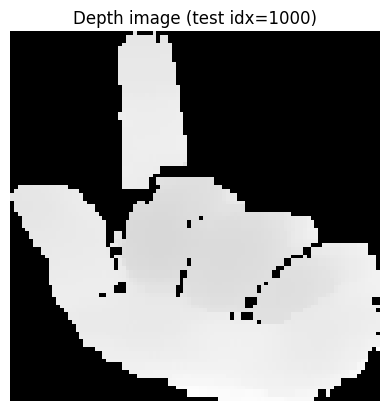

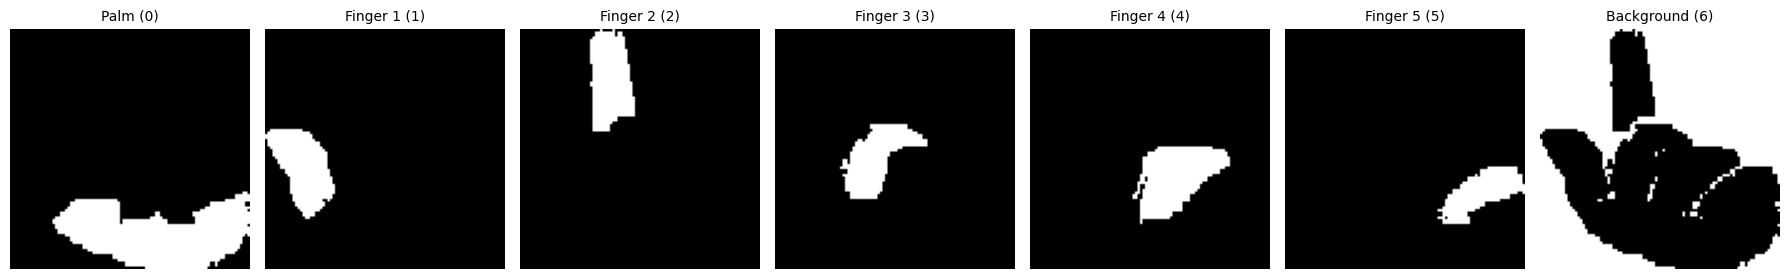

In [6]:
sample_idx = 1000
plt.imshow(x_test[sample_idx, 0], cmap='gray')
plt.title(f'Depth image (test idx={sample_idx})')
plt.axis('off')
plt.show()

class_names = ['Palm (0)', 'Finger 1 (1)', 'Finger 2 (2)', 'Finger 3 (3)', 'Finger 4 (4)', 'Finger 5 (5)', 'Background (6)']
plt.figure(figsize=(18, 4))
for cls_idx in range(n_classes):
    plt.subplot(1, n_classes, cls_idx + 1)
    plt.imshow((y_test[sample_idx] == cls_idx).astype(np.uint8), cmap='gray')
    plt.title(class_names[cls_idx], fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

# (2) Declare model

In [7]:
def conv_bn_relu(in_c, out_c, k=3, pad=1):
    return [
        ('conv', nn.Conv2d(in_c, out_c, kernel_size=k, padding=pad, bias=True)),
        ('bn', nn.BatchNorm2d(out_c)),
        ('relu', nn.ReLU(inplace=True)),
    ]


class SegNet(nn.Module):
    """Bản PyTorch tương đương 1-1 với kiến trúc SegNet (VGG16-style Encoder-Decoder) trong 1_segnet.ipynb gốc."""
    def __init__(self, in_channels=1, num_classes=7, k=3):
        super().__init__()
        enc_spec = [
            (in_channels, 64), (64, 64), None,
            (64, 128), (128, 128), None,
            (128, 256), (256, 256), (256, 256), None,
            (256, 512), (512, 512), (512, 512), None,
            (512, 512), (512, 512), (512, 512), None,
        ]
        enc_layers = []
        c_idx, p_idx = 1, 1
        for item in enc_spec:
            if item is None:
                enc_layers.append((f'enc_pool{p_idx}', nn.MaxPool2d(2)))
                p_idx += 1
            else:
                ci, co = item
                for suffix, mod in conv_bn_relu(ci, co, k=k, pad=k // 2):
                    enc_layers.append((f'enc_{suffix}{c_idx}', mod))
                c_idx += 1
        self.encoder = nn.Sequential(OrderedDict(enc_layers))

        dec_spec = [
            None, (512, 512), (512, 512), (512, 512),
            None, (512, 512), (512, 512), (512, 256),
            None, (256, 256), (256, 256), (256, 128),
            None, (128, 128), (128, 64),
            None, (64, 64),
        ]
        dec_layers = []
        d_idx, u_idx = 1, 1
        for item in dec_spec:
            if item is None:
                dec_layers.append((f'dec_up{u_idx}', nn.Upsample(scale_factor=2, mode='nearest')))
                u_idx += 1
            else:
                ci, co = item
                for suffix, mod in conv_bn_relu(ci, co, k=k, pad=k // 2):
                    dec_layers.append((f'dec_{suffix}{d_idx}', mod))
                d_idx += 1
        # Lớp phân loại 1x1 cuối + BatchNorm (bản gốc không có ReLU sau lớp cuối, chỉ softmax -> ở PyTorch trả về logits)
        dec_layers.append(('dec_conv_out', nn.Conv2d(64, num_classes, kernel_size=1, padding=0, bias=True)))
        dec_layers.append(('dec_bn_out', nn.BatchNorm2d(num_classes)))
        self.decoder = nn.Sequential(OrderedDict(dec_layers))

    def forward(self, x):
        return self.decoder(self.encoder(x))


model = SegNet(in_channels=1, num_classes=n_classes, k=kernel).to(device)
init_like_keras(model)
summary(model, (1, img_h, img_w))   # Keras gốc: Total 29,458,211 (Trainable 29,442,325 + Non-trainable BN 15,886)

Layer (type)                          Output Shape               Param #
encoder.enc_conv1 (Conv2d)            (None, 64, 96, 96)             640
encoder.enc_bn1 (BatchNorm2d)         (None, 64, 96, 96)             128
encoder.enc_relu1 (ReLU)              (None, 64, 96, 96)               0
encoder.enc_conv2 (Conv2d)            (None, 64, 96, 96)          36,928
encoder.enc_bn2 (BatchNorm2d)         (None, 64, 96, 96)             128
encoder.enc_relu2 (ReLU)              (None, 64, 96, 96)               0
encoder.enc_pool1 (MaxPool2d)         (None, 64, 48, 48)               0
encoder.enc_conv3 (Conv2d)            (None, 128, 48, 48)         73,856
encoder.enc_bn3 (BatchNorm2d)         (None, 128, 48, 48)            256
encoder.enc_relu3 (ReLU)              (None, 128, 48, 48)              0
encoder.enc_conv4 (Conv2d)            (None, 128, 48, 48)        147,584
encoder.enc_bn4 (BatchNorm2d)         (None, 128, 48, 48)            256
encoder.enc_relu4 (ReLU)              (None, 128, 4

# (3) Train defined model
- In case your system runs out of memory (OOM), try to use smaller batch size
- Cấu hình giống hệt bản Keras gốc: `Adam(lr=0.0001)`, `batch_size = 8`, `epochs = 15`, `nn.CrossEntropyLoss(ignore_index=-100)`.

In [8]:
lr = 0.0001
batch_size = 8
nb_epoch = 15

loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

train_loader = make_loader(x_train, y_train, batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size, shuffle=False)

start_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, nb_epoch)
training_time = time.time() - start_time
print(f'> training time: {training_time:.2f}s ({training_time / 60:.2f} minutes)')

Epoch  1/15 -  18.2s - loss: 1.1992 - acc: 0.6712 - val_loss: 1.1366 - val_acc: 0.6956


Epoch  2/15 -  17.5s - loss: 0.9002 - acc: 0.7986 - val_loss: 0.9924 - val_acc: 0.7493


Epoch  3/15 -  17.6s - loss: 0.7671 - acc: 0.8477 - val_loss: 0.9264 - val_acc: 0.7685


Epoch  4/15 -  17.7s - loss: 0.6872 - acc: 0.8719 - val_loss: 0.8468 - val_acc: 0.7945


Epoch  5/15 -  17.7s - loss: 0.6257 - acc: 0.8881 - val_loss: 0.8004 - val_acc: 0.8010


Epoch  6/15 -  17.7s - loss: 0.5778 - acc: 0.8986 - val_loss: 0.8105 - val_acc: 0.7962


... (5 outputs left out)

Epoch 12/15 -  17.8s - loss: 0.4048 - acc: 0.9246 - val_loss: 0.7078 - val_acc: 0.8148


Epoch 13/15 -  17.8s - loss: 0.3863 - acc: 0.9264 - val_loss: 0.7141 - val_acc: 0.8090


Epoch 14/15 -  17.8s - loss: 0.3663 - acc: 0.9290 - val_loss: 0.7042 - val_acc: 0.8091


Epoch 15/15 -  17.8s - loss: 0.3483 - acc: 0.9315 - val_loss: 0.6808 - val_acc: 0.8138
> training time: 266.25s (4.44 minutes)


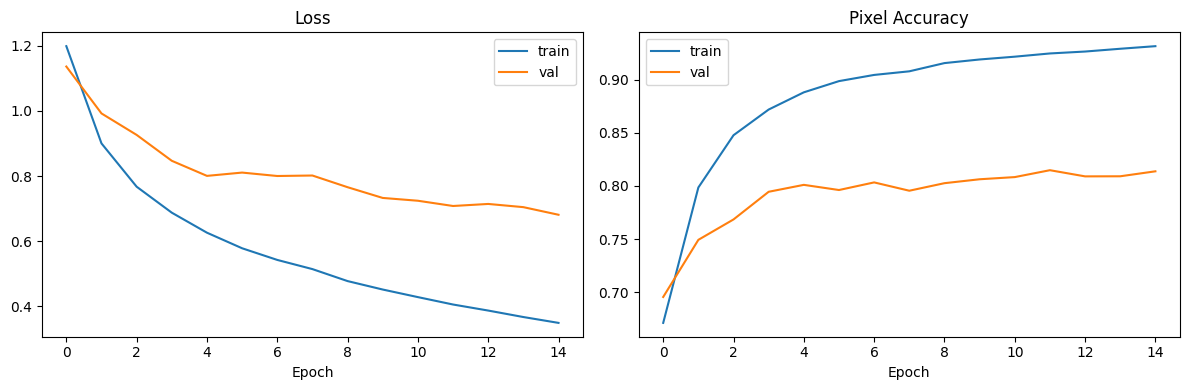

In [9]:
plot_history(history)

### Training time & So sánh bản gốc
- **Bản Keras gốc** (`examples/5. Others/1_segnet.ipynb`): 15 epoch, `training time = 750.02s` (`12.50` phút), `Test loss = 0.6860`, `Test pixel accuracy = 0.7732`.
- **Bản PyTorch**: xem kết quả chạy trực tiếp ở các ô trên và ô đánh giá dưới đây.

# (4) Evaluate trained model

In [10]:
score = evaluate(model, test_loader, loss_fn)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.6808141942251297
Test accuracy: 0.8137810686687502


In [11]:
def class_to_rgb(output_dis):
    """Ánh xạ bản đồ lớp (H, W) -> ảnh màu RGB (H, W, 3) giống hệt bản Keras gốc."""
    rgb_out = np.ones((img_h, img_w, 3), dtype=np.float32)

    rgb_out[output_dis == 0] = [0.0, 0.0, 0.0]   # palm
    rgb_out[output_dis == 1] = [0.0, 0.0, 0.5]   # finger 1
    rgb_out[output_dis == 2] = [0.0, 0.5, 0.0]   # finger 2
    rgb_out[output_dis == 3] = [0.5, 0.0, 0.0]   # finger 3
    rgb_out[output_dis == 4] = [0.5, 0.0, 0.5]   # finger 4
    rgb_out[output_dis == 5] = [0.5, 0.5, 0.0]   # finger 5
    rgb_out[output_dis == 6] = [1.0, 1.0, 1.0]   # background

    return rgb_out

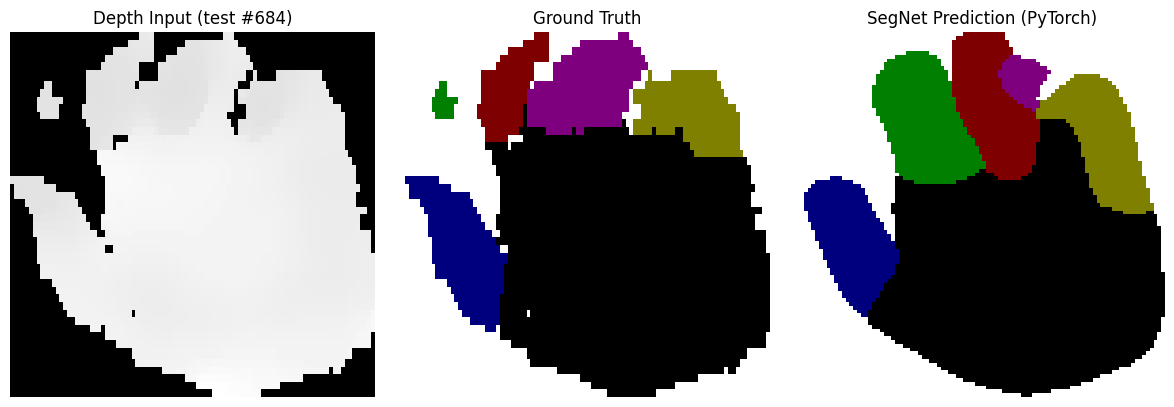

In [12]:
ran_ind = int(np.random.choice(range(x_test.shape[0]), 1)[0])
segnet_probs = predict(model, x_test[ran_ind:ran_ind + 1])  # (1, 7, 96, 96)
pred_map = np.argmax(segnet_probs[0], axis=0)               # (96, 96)
gt_map = np.where(y_test[ran_ind] >= 0, y_test[ran_ind], 6)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(x_test[ran_ind, 0], cmap='gray')
axes[0].set_title(f'Depth Input (test #{ran_ind})'); axes[0].axis('off')

axes[1].imshow(class_to_rgb(gt_map))
axes[1].set_title('Ground Truth'); axes[1].axis('off')

axes[2].imshow(class_to_rgb(pred_map))
axes[2].set_title('SegNet Prediction (PyTorch)'); axes[2].axis('off')

plt.tight_layout()
plt.show()